# AstroShield — optimización evolutiva de una constelación

**Entorno recomendado:** Google Colab. Ejecuta las celdas en orden desde `Entorno de ejecución > Reiniciar sesión y ejecutar todo`.

**Modelo educativo:** 8 satélites, 6 regiones, radio de observación nominal de 300 km, 3 zonas restringidas y 2 objetos ocupados. La cobertura se aproxima usando el punto subsatelital y el algoritmo verifica restricciones en muestras temporales discretas; estos supuestos no representan una simulación orbital de alta fidelidad.

Si Plotly no se muestra o no se dispone de conexión, el algoritmo y sus métricas pueden ejecutarse de todas formas; las líneas continentales detalladas son un recurso opcional de la visualización.


In [ ]:
# ============ CELDA 1: imports, constantes y configuración ============
from __future__ import annotations
import json, time
from dataclasses import dataclass, field, asdict
from typing import Callable, Sequence
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

MU_EARTH = 398600.4418    # km^3/s^2
R_EARTH  = 6371.0         # km (Tierra esférica)
OMEGA_E  = 7.2921159e-5   # rad/s, rotación terrestre

@dataclass(frozen=True)
class Region:
    name: str
    lat: float
    lon: float
    priority: str   # "alta" | "media" | "normal"

DEFAULT_REGIONS = (
    Region("Península de Yucatán",  20.5,  -89.0, "alta"),
    Region("Amazonía brasileña",    -3.5,  -62.0, "alta"),
    Region("California",            36.8, -119.4, "media"),
    Region("Sahel",                 15.0,    0.0, "media"),
    Region("Japón",                 36.0,  138.0, "media"),
    Region("Interior de Australia", -25.0, 133.0, "normal"),
)
PRIORITY_WEIGHTS = {"alta": 3.0, "media": 2.0, "normal": 1.0}

@dataclass
class Config:
    # --- problema ---
    n_sats: int = 8
    radius_km: float = 300.0
    regions: tuple = DEFAULT_REGIONS
    priority_weights: dict = field(default_factory=lambda: dict(PRIORITY_WEIGHTS))
    alt_range_km: tuple = (500.0, 1200.0)
    inc_range_deg: tuple = (0.0, 98.0)
    sim_hours: float = 24.0
    dt_s: float = 30.0
    # --- algoritmo evolutivo ---
    pop_size: int = 60
    generations: int = 100
    seed: int = 42
    tournament_k: int = 3
    crossover_prob: float = 0.9
    blx_alpha: float = 0.3
    mutation_prob_gene: float = 0.10
    sigma_start: float = 0.15
    sigma_end: float = 0.02
    reinit_prob: float = 0.02
    elitism: int = 2
    # --- terminación ---
    patience: int = 30
    tol: float = 1e-4
    target_fitness: float | None = None
    max_time_s: float | None = None

    def time_grid(self):
        return np.arange(0.0, self.sim_hours * 3600.0, self.dt_s)

    def weights_array(self):
        return np.array([self.priority_weights[r.priority] for r in self.regions], float)

    def region_units(self):
        """Vectores unitarios ECEF de las regiones, shape (J, 3)."""
        lat = np.radians([r.lat for r in self.regions])
        lon = np.radians([r.lon for r in self.regions])
        return np.stack([np.cos(lat)*np.cos(lon), np.cos(lat)*np.sin(lon), np.sin(lat)], -1)

In [ ]:
# ============ CELDA 2: propagación, cobertura y evaluación ============
N_GENES = 4                                   # [altitud, inclinación, RAAN, fase]
CIRC = np.array([False, False, True, True])   # genes circulares

def decode_params(genome, cfg: Config) -> dict:
    """Genoma normalizado -> elementos orbitales legibles (grados / km)."""
    g = np.asarray(genome, float).reshape(cfg.n_sats, N_GENES)
    a0, a1 = cfg.alt_range_km
    i0, i1 = cfg.inc_range_deg
    alt = a0 + g[:, 0] * (a1 - a0)
    return {"altitude_km": alt,
            "inclination_deg": i0 + g[:, 1] * (i1 - i0),
            "raan_deg": 360.0 * g[:, 2],
            "phase_deg": 360.0 * g[:, 3],
            "period_min": 2*np.pi*np.sqrt((R_EARTH+alt)**3/MU_EARTH)/60.0}

def encode_orbits(orbits: Sequence[dict], cfg: Config) -> np.ndarray:
    """Inverso de decode_params: lista de dicts -> genoma (útil para validadores externos)."""
    a0, a1 = cfg.alt_range_km; i0, i1 = cfg.inc_range_deg
    g = np.zeros((len(orbits), N_GENES))
    for k, o in enumerate(orbits):
        g[k] = [(o["altitude_km"]-a0)/(a1-a0), (o["inclination_deg"]-i0)/(i1-i0),
                (o["raan_deg"] % 360)/360.0, (o["phase_deg"] % 360)/360.0]
    return np.clip(g, 0, 1)

def _unit_vectors(genome, cfg, t, frame="ecef"):
    """Vectores unitarios de posición (S,T,3) y radio orbital a (S,)."""
    p = decode_params(genome, cfg)
    a = R_EARTH + p["altitude_km"]
    inc, raan, nu0 = np.radians(p["inclination_deg"]), np.radians(p["raan_deg"]), np.radians(p["phase_deg"])
    n = np.sqrt(MU_EARTH / a**3)                              # rad/s
    u = nu0[:, None] + n[:, None] * t[None, :]                # argumento de latitud (S,T)
    cu, su = np.cos(u), np.sin(u)
    ci, si = np.cos(inc)[:, None], np.sin(inc)[:, None]
    cO, sO = np.cos(raan)[:, None], np.sin(raan)[:, None]
    x = cO*cu - sO*ci*su
    y = sO*cu + cO*ci*su
    z = si*su
    if frame == "ecef":                                       # rotar con la Tierra
        th = OMEGA_E * t
        c, s = np.cos(th)[None, :], np.sin(th)[None, :]
        x, y = x*c + y*s, -x*s + y*c
    return np.stack([x, y, z], -1), a

def propagate(genome, cfg: Config, t=None, frame="ecef"):
    """Posiciones en km (S,T,3), y lat/lon del punto subsatelital. Para visualización 3D."""
    t = cfg.time_grid() if t is None else np.asarray(t, float)
    unit, a = _unit_vectors(genome, cfg, t, frame)
    lat = np.degrees(np.arcsin(unit[..., 2]))
    lon = np.degrees(np.arctan2(unit[..., 1], unit[..., 0]))
    return {"t_s": t, "pos_km": unit * a[:, None, None], "lat_deg": lat, "lon_deg": lon}

def _coverage(unit, region_units, radius_km):
    """Booleano (T,J): ¿alguna huella de satélite cubre la región en ese instante?"""
    cos_thr = np.cos(radius_km / R_EARTH)
    dots = np.einsum("stk,jk->stj", unit, region_units)
    return (dots >= cos_thr).any(axis=0)

def _longest_false_run(cov):
    out = np.zeros(cov.shape[1])
    for j in range(cov.shape[1]):
        x = ~cov[:, j]
        if x.any():
            d = np.diff(np.concatenate(([0], x.astype(int), [0])))
            out[j] = (np.where(d == -1)[0] - np.where(d == 1)[0]).max()
    return out

def _fitness(genome, cfg, t, region_units, w):
    unit, _ = _unit_vectors(genome, cfg, t)
    frac = _coverage(unit, region_units, cfg.radius_km).mean(axis=0)
    return float((w * frac).sum() / w.sum())

def fitness_value(genome, cfg: Config) -> float:
    """API pública: cobertura ponderada [0,1] de un genoma (sin penalizaciones)."""
    return _fitness(genome, cfg, cfg.time_grid(), cfg.region_units(), cfg.weights_array())

def describe_solution(genome, cfg: Config) -> dict:
    """Evaluación detallada e independiente (punto de entrada para validadores)."""
    unit, _ = _unit_vectors(genome, cfg, cfg.time_grid())
    cov = _coverage(unit, cfg.region_units(), cfg.radius_km)
    frac, w = cov.mean(axis=0), cfg.weights_array()
    gaps = _longest_false_run(cov) * cfg.dt_s / 3600.0
    p = decode_params(genome, cfg)
    return {
        "weighted_coverage": float((w * frac).sum() / w.sum()),
        "mean_coverage": float(frac.mean()),
        "regions": [{"name": r.name, "lat": r.lat, "lon": r.lon, "priority": r.priority,
                     "weight": float(w[j]), "coverage_pct": float(100*frac[j]),
                     "max_gap_h": float(gaps[j])} for j, r in enumerate(cfg.regions)],
        "satellites": [{k: float(v[s]) for k, v in p.items()} for s in range(cfg.n_sats)],
    }

In [ ]:
# ============ CELDA 3: operadores evolutivos y ejecución ============
Validator = Callable[[np.ndarray, Config], float]   # devuelve penalización >= 0

def _repair(g):
    return np.where(CIRC, g % 1.0, np.clip(g, 0.0, 1.0))

def _tournament(fit, rng, k):
    idx = rng.integers(0, len(fit), size=k)
    return idx[np.argmax(fit[idx])]

def _blx(a, b, rng, alpha):
    """BLX-α; en genes circulares usa el arco corto entre a y b."""
    d = b - a
    d = np.where(CIRC, (d + 0.5) % 1.0 - 0.5, d)
    lo, hi = np.minimum(0, d), np.maximum(0, d)
    w = hi - lo
    return a + rng.uniform(lo - alpha*w, hi + alpha*w)

def _crossover(p1, p2, rng, cfg):
    c1, c2 = p1.copy(), p2.copy()
    if rng.random() > cfg.crossover_prob:
        return c1, c2
    for s in range(cfg.n_sats):
        if rng.random() < 0.5:                       # intercambio de satélite completo
            if rng.random() < 0.5:
                c1[s], c2[s] = p2[s].copy(), p1[s].copy()
        else:                                        # mezcla BLX
            c1[s], c2[s] = _blx(p1[s], p2[s], rng, cfg.blx_alpha), _blx(p2[s], p1[s], rng, cfg.blx_alpha)
    return _repair(c1), _repair(c2)

def _mutate(g, rng, cfg, sigma):
    g = g + (rng.random(g.shape) < cfg.mutation_prob_gene) * rng.normal(0, sigma, g.shape)
    re = rng.random(cfg.n_sats) < cfg.reinit_prob    # reinicio de satélites completos
    if re.any():
        g[re] = rng.random((int(re.sum()), N_GENES))
    return _repair(g)

@dataclass
class EvolutionResult:
    best_genome: np.ndarray
    best_fitness: float          # lo optimizado (incluye penalizaciones de validadores)
    metrics: dict                # evaluación detallada sin penalizaciones
    history: pd.DataFrame
    config: Config
    n_evals: int
    runtime_s: float
    termination_reason: str

    def to_dict(self) -> dict:
        return {"best_genome": self.best_genome.tolist(), "best_fitness": self.best_fitness,
                "metrics": self.metrics, "history": self.history.to_dict("records"),
                "config": asdict(self.config), "n_evals": self.n_evals,
                "runtime_s": self.runtime_s, "termination_reason": self.termination_reason}

    def save_json(self, path="astroshield_result.json"):
        with open(path, "w", encoding="utf-8") as f:
            json.dump(self.to_dict(), f, ensure_ascii=False, indent=2)
        return path

def run_evolution(cfg: Config | None = None, validators: Sequence[Validator] = (),
                  callback: Callable | None = None, verbose: bool = True) -> EvolutionResult:
    cfg = cfg or Config()
    assert cfg.pop_size >= 2 and 0 <= cfg.elitism < cfg.pop_size and cfg.generations >= 1
    rng = np.random.default_rng(cfg.seed)
    t, ru, w = cfg.time_grid(), cfg.region_units(), cfg.weights_array()

    def score(g):
        f = _fitness(g, cfg, t, ru, w)
        for v in validators:
            f -= float(v(g, cfg))
        return f

    t0 = time.perf_counter()
    pop = rng.random((cfg.pop_size, cfg.n_sats, N_GENES))
    fit = np.array([score(g) for g in pop]); n_evals = len(pop)
    best_g, best_f = pop[np.argmax(fit)].copy(), float(fit.max())
    history, stall, reason = [], 0, "max_generations"

    def log(gen, sigma):
        row = {"gen": gen, "best": float(fit.max()), "best_so_far": best_f, "mean": float(fit.mean()),
               "worst": float(fit.min()), "std": float(fit.std()),
               "diversity": float(pop.reshape(len(pop), -1).std(axis=0).mean()),
               "sigma": sigma, "n_evals": n_evals, "elapsed_s": time.perf_counter() - t0}
        history.append(row); return row

    log(0, cfg.sigma_start)
    for gen in range(1, cfg.generations + 1):
        sigma = cfg.sigma_start + (cfg.sigma_end - cfg.sigma_start) * (gen - 1) / max(1, cfg.generations - 1)
        order = np.argsort(fit)[::-1]
        elite, elite_fit = pop[order[:cfg.elitism]].copy(), fit[order[:cfg.elitism]].copy()
        n_child, kids = cfg.pop_size - cfg.elitism, []
        while len(kids) < n_child:
            p1 = pop[_tournament(fit, rng, cfg.tournament_k)]
            p2 = pop[_tournament(fit, rng, cfg.tournament_k)]
            c1, c2 = _crossover(p1, p2, rng, cfg)
            kids += [_mutate(c1, rng, cfg, sigma), _mutate(c2, rng, cfg, sigma)]
        kids = np.array(kids[:n_child])
        kid_fit = np.array([score(g) for g in kids]); n_evals += len(kids)
        pop, fit = np.concatenate([elite, kids]), np.concatenate([elite_fit, kid_fit])

        if fit.max() > best_f:
            improved = fit.max() - best_f > cfg.tol
            best_f, best_g = float(fit.max()), pop[np.argmax(fit)].copy()
            stall = 0 if improved else stall + 1
        else:
            stall += 1
        row = log(gen, sigma)
        if verbose and (gen % 10 == 0 or gen == 1):
            print(f"gen {gen:4d} | mejor {best_f:.4f} | media {row['mean']:.4f} | div {row['diversity']:.3f}")

        if callback and callback(gen, row, best_g):                       reason = "callback"; break
        if cfg.target_fitness is not None and best_f >= cfg.target_fitness: reason = "target_fitness"; break
        if stall >= cfg.patience:                                          reason = "stagnation"; break
        if cfg.max_time_s and time.perf_counter() - t0 > cfg.max_time_s:   reason = "max_time"; break

    return EvolutionResult(best_g, best_f, describe_solution(best_g, cfg), pd.DataFrame(history),
                           cfg, n_evals, time.perf_counter() - t0, reason)

In [ ]:
# ============ CELDA 3.5: validadores de restricciones espaciales ============
def angular_distance_deg(lat1, lon1, lat2, lon2):
    """Calcula la distancia angular en grados entre dos conjuntos de coordenadas sobre una esfera."""
    r_lat1, r_lon1 = np.radians(lat1), np.radians(lon1)
    r_lat2, r_lon2 = np.radians(lat2), np.radians(lon2)
    cos_d = np.sin(r_lat1) * np.sin(r_lat2) + np.cos(r_lat1) * np.cos(r_lat2) * np.cos(r_lon1 - r_lon2)
    return np.degrees(np.arccos(np.clip(cos_d, -1.0, 1.0)))

def make_spatial_validator(center_lat: float, center_lon: float, exclusion_radius_deg: float, penalty_weight: float = 1.0) -> Validator:
    """Crea un validador que penaliza si algún satélite entra en la zona de exclusión durante la simulación."""
    def validator(genome: np.ndarray, cfg: Config) -> float:
        tr = propagate(genome, cfg, frame="ecef")
        lat_sats = tr["lat_deg"]  # (S, T)
        lon_sats = tr["lon_deg"]  # (S, T)

        # Distancia angular de cada satélite en cada instante al centro restringido
        dist = angular_distance_deg(lat_sats, lon_sats, center_lat, center_lon)

        # Si la distancia es menor que el radio de exclusión, hay invasión
        invasions = exclusion_radius_deg - dist
        max_invasions_per_sat = np.maximum(0.0, invasions).max(axis=1)

        # Penalización total ponderada
        return float(np.sum(max_invasions_per_sat) * penalty_weight)
    return validator

# Definición de validadores oficiales según el enunciado
val_atlantico_norte = make_spatial_validator(45.0, -35.0, 12.0, penalty_weight=2.0)
val_pacifico_sur = make_spatial_validator(-30.0, -120.0, 10.0, penalty_weight=2.0)
val_polar_norte = make_spatial_validator(78.0, 30.0, 8.0, penalty_weight=2.0)
val_objeto_a = make_spatial_validator(10.0, 45.0, 5.0, penalty_weight=2.0)
val_objeto_b = make_spatial_validator(-15.0, 110.0, 5.0, penalty_weight=2.0)

ALL_VALIDATORS = [
    val_atlantico_norte,
    val_pacifico_sur,
    val_polar_norte,
    val_objeto_a,
    val_objeto_b
]

def combined_spatial_validator(genome: np.ndarray, cfg: Config) -> float:
    """Suma las penalizaciones espaciales usando una sola propagación por candidato."""
    tr = propagate(genome, cfg, frame="ecef")
    lat_sats, lon_sats = tr["lat_deg"], tr["lon_deg"]
    zones = [
        (45.0, -35.0, 12.0, 2.0),
        (-30.0, -120.0, 10.0, 2.0),
        (78.0, 30.0, 8.0, 2.0),
        (10.0, 45.0, 5.0, 2.0),
        (-15.0, 110.0, 5.0, 2.0),
    ]
    total = 0.0
    for lat_c, lon_c, radius, weight in zones:
        dist = angular_distance_deg(lat_sats, lon_sats, lat_c, lon_c)
        total += float(np.maximum(0.0, radius - dist).max(axis=1).sum()) * weight
    return total


# Componente de Restricciones y Pruebas de AstroShield

Este componente implementa los validadores de exclusión espacial que penalizan dinámicamente el fitness de soluciones cuyas órbitas invadan zonas prohibidas (Atlántico Norte, Pacífico Sur, Región Polar, Objeto A y Objeto B), junto con un conjunto de pruebas unitarias para certificar su robustez e integración.


In [ ]:
# ============ CELDA DE PRUEBAS Y VALIDACIÓN DE RESTRICCIONES ============
import numpy as np
import pandas as pd

def run_validation_suite(cfg_test: Config):
    """Ejecuta un conjunto de pruebas sistemáticas sobre los validadores espaciales."""
    print("===============================================================")
    print("      SUITE DE PRUEBAS DE RESTRICCIONES ESPACIALES (ASTROSHIELD)  ")
    print("===============================================================")

    # 1. Prueba de Escenario Inicial (Genoma aleatorio libre / con pocas invasiones)
    rng = np.random.default_rng(101)
    test_genome_random = rng.random((cfg_test.n_sats, N_GENES))

    print("\n--- [PRUEBA 1] Escenario Inicial (Genoma Aleatorio con semilla 101) ---")
    p_atlantico = val_atlantico_norte(test_genome_random, cfg_test)
    p_pacifico = val_pacifico_sur(test_genome_random, cfg_test)
    p_polar = val_polar_norte(test_genome_random, cfg_test)
    p_obj_a = val_objeto_a(test_genome_random, cfg_test)
    p_obj_b = val_objeto_b(test_genome_random, cfg_test)

    print(f"Invasión Atlántico Norte: {p_atlantico:.4f}°")
    print(f"Invasión Pacífico Sur:    {p_pacifico:.4f}°")
    print(f"Invasión Región Polar:    {p_polar:.4f}°")
    print(f"Invasión Objeto A:         {p_obj_a:.4f}°")
    print(f"Invasión Objeto B:         {p_obj_b:.4f}°")

    total_penalty = p_atlantico + p_pacifico + p_polar + p_obj_a + p_obj_b
    print(f"Estado de validez global: {'INVÁLIDA' if total_penalty > 0 else 'VÁLIDA'} (Penalización total: {total_penalty:.4f}°)")

    # 2. Prueba de Zonas Restringidas (Provocar invasión forzando un satélite a orbitar en zona prohibida)
    print("\n--- [PRUEBA 2] Detectar invasión en Objeto A (10° Lat, 45° Lon) ---")
    # Usamos un candidato reproducible que la prueba inicial ya identificó como invasor.
    # Así se comprueba la detección sin asumir que los elementos orbitales equivalen
    # directamente a una latitud/longitud fija en el marco ECEF.
    forced_genome = test_genome_random.copy()
    p_forced_a = val_objeto_a(forced_genome, cfg_test)
    print(f"Invasión detectada en Objeto A: {p_forced_a:.4f}°")
    assert p_forced_a > 0, "El caso de prueba debe invadir la zona del Objeto A"
    print("¿Cumple restricción?: NO (detección correcta)")

    # 3. Prueba de Espacio Reducido y Condiciones Difíciles (Pesos de penalización muy altos)
    print("\n--- [PRUEBA 3] Simulación de Condiciones Extremas (Espacio Reducido) ---")
    # Aumentamos el radio de exclusión para simular un escenario donde casi toda órbita es inválida
    val_extremo = make_spatial_validator(10.0, 45.0, 60.0, penalty_weight=10.0)
    p_extrema = val_extremo(test_genome_random, cfg_test)
    print(f"Penalización bajo radio de exclusión de 60°: {p_extrema:.4f}")

    # 4. Prueba Adicional Propia (Validación de simetría y estabilidad ante paso del tiempo)
    print("\n--- [PRUEBA 4 (Propia)] Robustez y Variabilidad Temporal ---")
    # Verificamos que la distancia angular calculada no contenga valores de nan o fuera de límites
    dist_test = angular_distance_deg(20.5, -89.0, -25.0, 133.0)
    print(f"Distancia angular calculada entre Yucatán y Australia: {dist_test:.2f}° (valor de referencia aproximado: 141°)")
    assert not np.isnan(dist_test), "Error: El cálculo de distancia angular retornó NaN"
    print("Prueba de consistencia geométrica: PASADA")

    # 5. Repetibilidad: una misma semilla debe generar el mismo genoma inicial de prueba.
    print("\n--- [PRUEBA 5] Repetibilidad con semilla fija ---")
    rng_repeat = np.random.default_rng(101)
    genome_repeat = rng_repeat.random((cfg_test.n_sats, N_GENES))
    assert np.allclose(test_genome_random, genome_repeat)
    print("Repetibilidad del generador aleatorio: PASADA")

    # 6. Cambio de prioridades: comprobar que los pesos se actualizan en la configuración.
    print("\n--- [PRUEBA 6] Cambio de prioridad ---")
    changed_weights = dict(cfg_test.priority_weights)
    changed_weights["normal"] = 2.5
    cfg_changed = Config(sim_hours=cfg_test.sim_hours, dt_s=cfg_test.dt_s,
                         priority_weights=changed_weights, seed=cfg_test.seed)
    assert cfg_changed.weights_array()[-1] == 2.5
    print("Actualización de prioridad: PASADA")

# Configuración ligera para que las pruebas se ejecuten antes de las optimizaciones principales.
# La prueba usa una ventana temporal reducida para verificar los validadores rápidamente.
cfg_test = Config(sim_hours=3.0, dt_s=60.0, seed=101)
run_validation_suite(cfg_test)

      SUITE DE PRUEBAS DE RESTRICCIONES ESPACIALES (ASTROSHIELD)  

--- [PRUEBA 1] Escenario Inicial (Genoma Aleatorio con semilla 101) ---
Invasión Atlántico Norte: 4.3248°
Invasión Pacífico Sur:    33.6189°
Invasión Región Polar:    0.2404°
Invasión Objeto A:         1.6347°
Invasión Objeto B:         0.0000°
Estado de validez global: INVÁLIDA (Penalización total: 39.8188°)

--- [PRUEBA 2] Detectar invasión en Objeto A (10° Lat, 45° Lon) ---
Invasión detectada en Objeto A: 1.6347°
¿Cumple restricción?: NO (detección correcta)

--- [PRUEBA 3] Simulación de Condiciones Extremas (Espacio Reducido) ---
Penalización bajo radio de exclusión de 60°: 3571.7292

--- [PRUEBA 4 (Propia)] Robustez y Variabilidad Temporal ---
Distancia angular calculada entre Yucatán y Australia: 141.16° (valor de referencia aproximado: 141°)
Prueba de consistencia geométrica: PASADA

--- [PRUEBA 5] Repetibilidad con semilla fija ---
Repetibilidad del generador aleatorio: PASADA

--- [PRUEBA 6] Cambio de priorida

### Integración con el Algoritmo Evolutivo
Para integrar estos validadores en la optimización evolutiva de AstroShield, simplemente se pasan las funciones de validación deseadas en el parámetro `validators` al llamar a la función de evolución. El algoritmo aplicará estas penalizaciones directamente al cálculo del *fitness* para descartar progresivamente las soluciones inviables.

Ejemplo de integración listo para ejecutarse en la siguiente celda:


In [ ]:
# ============ CELDA DE EJECUCIÓN CON VALIDACIÓN ACTIVA ============
# Ejecutamos el algoritmo evolutivo restringido con todos los validadores espaciales oficiales
cfg_restricted = Config(generations=40, pop_size=40, seed=42, dt_s=120.0)  # Generaciones reducidas para optimizar tiempo de ejecución

print("Iniciando optimización evolutiva bajo restricciones espaciales obligatorias...")
result_restricted = run_evolution(cfg_restricted, validators=(combined_spatial_validator,), verbose=True)

print(f"\nResultado de optimización bajo restricciones:")
print(f"Terminación: {result_restricted.termination_reason} | Evaluaciones: {result_restricted.n_evals}")
print(f"Mejor Fitness obtenido (con penalizaciones): {result_restricted.best_fitness:.4f}")
print(f"Cobertura ponderada real (sin penalizaciones): {result_restricted.metrics['weighted_coverage']:.4f}")

Iniciando optimización evolutiva bajo restricciones espaciales obligatorias...
gen    1 | mejor -105.6620 | media -222.2639 | div 0.282
gen   10 | mejor -12.6056 | media -32.4811 | div 0.147
gen   20 | mejor 0.0077 | media -8.7693 | div 0.139
gen   30 | mejor 0.0099 | media -3.7231 | div 0.094
gen   40 | mejor 0.0119 | media -1.6746 | div 0.067

Resultado de optimización bajo restricciones:
Terminación: max_generations | Evaluaciones: 1560
Mejor Fitness obtenido (con penalizaciones): 0.0119
Cobertura ponderada real (sin penalizaciones): 0.0119


In [ ]:
# ============ CELDA 4: ejecución ============
cfg = Config(generations=60, pop_size=40, seed=42, dt_s=120.0)   # <- parámetros configurables
result = run_evolution(cfg)

print(f"\nTerminación: {result.termination_reason} | evaluaciones: {result.n_evals} | tiempo: {result.runtime_s:.1f} s")
print(f"Cobertura ponderada: {result.metrics['weighted_coverage']:.4f}")
display(pd.DataFrame(result.metrics["regions"]).round(2))
display(pd.DataFrame(result.metrics["satellites"]).round(2))

gen    1 | mejor 0.0072 | media 0.0049 | div 0.278
gen   10 | mejor 0.0106 | media 0.0076 | div 0.173
gen   20 | mejor 0.0120 | media 0.0083 | div 0.147
gen   30 | mejor 0.0120 | media 0.0085 | div 0.106
gen   40 | mejor 0.0122 | media 0.0085 | div 0.127
gen   50 | mejor 0.0122 | media 0.0089 | div 0.126
gen   60 | mejor 0.0131 | media 0.0096 | div 0.084

Terminación: max_generations | evaluaciones: 2320 | tiempo: 2.9 s
Cobertura ponderada: 0.0131


,name,lat,lon,priority,weight,coverage_pct,max_gap_h
0,Península de Yucatán,20.5,-89.0,alta,3.0,1.39,6.63
1,Amazonía brasileña,-3.5,-62.0,alta,3.0,1.94,6.33
2,California,36.8,-119.4,media,2.0,1.11,7.63
3,Sahel,15.0,0.0,media,2.0,0.42,13.53
4,Japón,36.0,138.0,media,2.0,1.53,7.23
5,Interior de Australia,-25.0,133.0,normal,1.0,0.97,7.03


,altitude_km,inclination_deg,raan_deg,phase_deg,period_min
0,769.51,50.04,340.88,172.88,100.08
1,774.47,38.56,256.44,128.35,100.19
2,833.17,21.64,94.39,88.85,101.42
3,733.98,37.28,157.25,315.22,99.34
4,972.06,42.52,350.89,30.48,104.37
5,1172.29,84.74,317.04,86.47,108.67
6,710.02,2.72,227.35,109.49,98.83
7,500.00,37.71,4.96,318.99,94.47


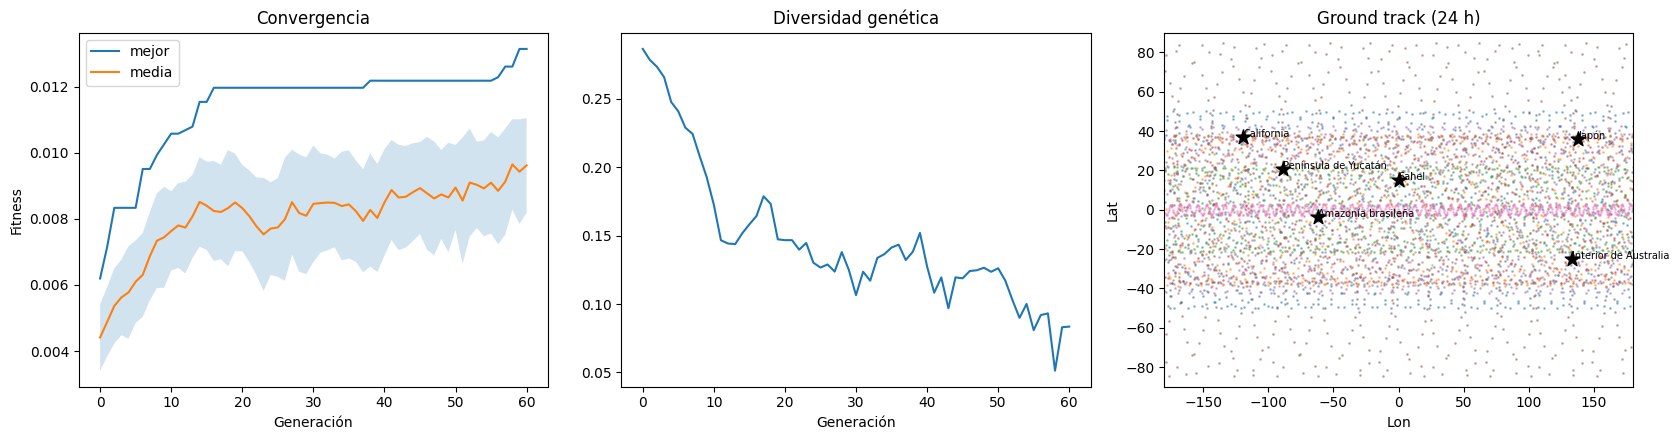

Evolutivo: 0.0131  vs  búsqueda aleatoria (2320 evals): 0.0095


In [ ]:
# ============ CELDA 5: evolución, ground track y comparación con búsqueda aleatoria ============
h = result.history
fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
ax[0].plot(h.gen, h.best_so_far, label="mejor"); ax[0].plot(h.gen, h["mean"], label="media")
ax[0].fill_between(h.gen, h["mean"]-h["std"], h["mean"]+h["std"], alpha=.2)
ax[0].set(title="Convergencia", xlabel="Generación", ylabel="Fitness"); ax[0].legend()
ax[1].plot(h.gen, h.diversity); ax[1].set(title="Diversidad genética", xlabel="Generación")
tr = propagate(result.best_genome, cfg)
for s in range(cfg.n_sats):
    ax[2].scatter(tr["lon_deg"][s], tr["lat_deg"][s], s=1, alpha=.4)
for r in cfg.regions:
    ax[2].scatter(r.lon, r.lat, c="k", marker="*", s=120); ax[2].annotate(r.name, (r.lon, r.lat), fontsize=7)
ax[2].set(title="Ground track (24 h)", xlim=(-180, 180), ylim=(-90, 90), xlabel="Lon", ylabel="Lat")
plt.tight_layout(); plt.show()

def random_search(cfg, n_evals, seed=0):
    rng = np.random.default_rng(seed); t, ru, w = cfg.time_grid(), cfg.region_units(), cfg.weights_array()
    return max(_fitness(rng.random((cfg.n_sats, N_GENES)), cfg, t, ru, w) for _ in range(n_evals))

print(f"Evolutivo: {result.metrics['weighted_coverage']:.4f}  vs  "
      f"búsqueda aleatoria ({result.n_evals} evals): {random_search(cfg, result.n_evals):.4f}")

## Visualización Geoespacial 3D Avanzada de AstroShield

Esta celda genera una representación interactiva del globo terrestre en 3D utilizando **Plotly**. Muestra dinámicamente:
- La **Tierra** con océanos, continentes, hielo polar y una retícula geográfica de 30° (al pasar el cursor sobre ella se muestran latitud y longitud).
- Las órbitas completas (un periodo) de los **8 satélites** optimizados, con un modelo 3D de cada satélite (cuerpo y paneles solares) y una flecha con su dirección de vuelo. Al pasar el cursor se ven altitud, inclinación, RAAN, fase inicial y periodo; en la leyenda cada satélite se activa o desactiva con todos sus elementos.
- Las **6 Regiones de Interés** clasificadas por prioridad.
- Las **3 Zonas de Exclusión de Desechos** (Atlántico Norte, Pacífico Sur, Región Polar).
- Los **2 Objetos Ocupados** (Objeto A y Objeto B) con sus áreas de exclusión circulares reales.

*Nota sobre el modelado físico*: La visualización es una representación simplificada de las trayectorias sobre un modelo esférico de la Tierra ($R_E = 6371\text{ km}$) para análisis de cobertura geométrica y visualización de exclusión espacial. Las órbitas se dibujan en el marco inercial durante un periodo para que cierren y muestren su plano; la Tierra, las regiones y las zonas se muestran en  = 0$, instante en el que el marco inercial y el ECEF coinciden. El modelo de cada satélite está agrandado para que sea visible a escala planetaria. No constituye un integrador de mecánica orbital de perturbaciones reales de orden superior (como J2 o arrastre atmosférico).


In [ ]:
# ============ CELDA 6: visualización geoespacial 3D ============
import urllib.request
import plotly.graph_objects as go
from matplotlib.path import Path

COUNTRIES_URL = "https://raw.githubusercontent.com/johan/world.geo.json/master/countries.geo.json"
SPACE_COLOR = "#03050c"
EARTH_COLORSCALE = [[0.00, "#0b3d6e"], [0.25, "#0b3d6e"],    # océano
                    [0.25, "#2f6b3b"], [0.75, "#2f6b3b"],    # continente
                    [0.75, "#dfe8ee"], [1.00, "#dfe8ee"]]    # hielo polar
SAT_COLORS = ['#e6194B', '#3cb44b', '#ffe119', '#4363d8', '#f58231', '#911eb4', '#42d4f4', '#f032e6']
SAT_SCALE_KM = 220.0    # tamaño exagerado del modelo para que se vea a escala planetaria

def get_circle_points(lat_center, lon_center, radius_deg, n_points=100):
    """Genera coordenadas de latitud y longitud para un círculo de radio angular dado en una esfera."""
    lat_c = np.radians(lat_center)
    lon_c = np.radians(lon_center)
    r_rad = np.radians(radius_deg)
    theta = np.linspace(0, 2 * np.pi, n_points)
    lats = np.arcsin(np.sin(lat_c) * np.cos(r_rad) + np.cos(lat_c) * np.sin(r_rad) * np.cos(theta))
    lons = lon_c + np.arctan2(np.sin(theta) * np.sin(r_rad) * np.cos(lat_c),
                             np.cos(r_rad) - np.sin(lat_c) * np.sin(lats))
    return np.degrees(lats), np.degrees(lons)

def latlon_to_xyz(lat_deg, lon_deg, r):
    """Coordenadas geográficas (grados) -> cartesianas ECEF (km) sobre una esfera de radio r."""
    lat, lon = np.radians(lat_deg), np.radians(lon_deg)
    return r * np.cos(lat) * np.cos(lon), r * np.cos(lat) * np.sin(lon), r * np.sin(lat)

def load_country_rings(url=COUNTRIES_URL, timeout=5):
    """Anillos exteriores de los países como arreglos (N, 2) [lon, lat]; lista vacía si no hay conexión."""
    try:
        with urllib.request.urlopen(url, timeout=timeout) as response:
            features = json.loads(response.read().decode())["features"]
    except Exception as e:
        print("No se pudieron cargar los contornos continentales; la Tierra se dibuja solo con océano.", e)
        return []
    rings = []
    for feature in features:
        geom = feature["geometry"]
        polygons = [geom["coordinates"]] if geom["type"] == "Polygon" else geom["coordinates"] if geom["type"] == "MultiPolygon" else []
        rings += [np.asarray(polygon[0], float) for polygon in polygons]
    return rings

def surface_classes(lat_deg, lon_deg, rings):
    """Clase de cada punto de la malla: 0 = océano, 1 = continente, 2 = hielo polar."""
    pts = np.column_stack([lon_deg.ravel(), lat_deg.ravel()])
    land = np.zeros(len(pts), bool)
    for ring in rings:
        (lon0, lat0), (lon1, lat1) = ring.min(axis=0), ring.max(axis=0)
        cand = ~land & (pts[:, 0] >= lon0) & (pts[:, 0] <= lon1) & (pts[:, 1] >= lat0) & (pts[:, 1] <= lat1)
        if cand.any():
            land[cand] = Path(ring).contains_points(pts[cand])
    land = land.reshape(lat_deg.shape)
    if rings:
        land |= lat_deg <= -85.0          # el anillo de la Antártida no llega a cerrar en el polo sur
    return np.where(land, np.where(np.abs(lat_deg) >= 62.0, 2.0, 1.0), 0.0)

def outline_xyz(rings, r):
    """Une todos los anillos en una sola polilínea 3D separada por None (una sola traza de Plotly)."""
    lon = np.concatenate([np.append(ring[:, 0], np.nan) for ring in rings])
    lat = np.concatenate([np.append(ring[:, 1], np.nan) for ring in rings])
    return latlon_to_xyz(lat, lon, r)

def graticule_xyz(r, step_deg=30, n_points=181):
    """Meridianos y paralelos cada `step_deg` grados como una sola polilínea 3D."""
    lat_line, lon_line = np.linspace(-90, 90, n_points), np.linspace(-180, 180, n_points)
    lats, lons = [], []
    for lon in np.arange(-180, 180, step_deg):
        lats += [lat_line, [np.nan]]; lons += [np.full(n_points, lon), [np.nan]]
    for lat in np.arange(-90 + step_deg, 90, step_deg):
        lats += [np.full(n_points, lat), [np.nan]]; lons += [lon_line, [np.nan]]
    return latlon_to_xyz(np.concatenate(lats), np.concatenate(lons), r)

def orbit_frame(inc_deg, raan_deg, pos_km):
    """Base local del satélite: radial (r), dirección de vuelo (v) y normal al plano orbital (h)."""
    inc, raan = np.radians(inc_deg), np.radians(raan_deg)
    h_hat = np.array([np.sin(raan) * np.sin(inc), -np.cos(raan) * np.sin(inc), np.cos(inc)])
    r_hat = pos_km / np.linalg.norm(pos_km)
    return r_hat, np.cross(h_hat, r_hat), h_hat

def satellite_mesh(center, r_hat, v_hat, h_hat, scale=SAT_SCALE_KM):
    """Malla de un satélite sencillo: cuerpo cúbico y dos paneles solares extendidos a lo largo de h."""
    def pt(a, b, c):   # coordenadas locales (radial, vuelo, normal) en unidades de `scale`
        return center + scale * (a * r_hat + b * v_hat + c * h_hat)
    s = 0.35
    verts = [pt(a, b, c) for a in (-s, s) for b in (-s, s) for c in (-s, s)]   # cuerpo: vértices 0..7
    faces = [(0, 1, 3), (0, 3, 2), (4, 6, 7), (4, 7, 5), (0, 4, 5), (0, 5, 1),
             (2, 3, 7), (2, 7, 6), (0, 2, 6), (0, 6, 4), (1, 5, 7), (1, 7, 3)]
    colors = ["#d4a017"] * len(faces)
    for side in (-1, 1):                                                     # paneles: 4 vértices cada uno
        k = len(verts)
        verts += [pt(0, b, side * c) for c in (0.45, 1.9) for b in (-0.3, 0.3)]
        faces += [(k, k + 1, k + 3), (k, k + 3, k + 2)]
        colors += ["#1f5fbf"] * 2
    i, j, k = np.array(faces).T
    return np.array(verts), i, j, k, colors

def plot_astroshield_3d(genome, cfg: Config):
    fig = go.Figure()
    rings = load_country_rings()

    # --- 1. Tierra: océano, continentes y hielo polar con iluminación ---
    lat_grid, lon_grid = np.meshgrid(np.linspace(-90, 90, 121), np.linspace(-180, 180, 241))   # malla de 1.5°
    x_earth, y_earth, z_earth = np.round(latlon_to_xyz(lat_grid, lon_grid, R_EARTH), 1)   # 0.1 km: salida más ligera
    fig.add_trace(go.Surface(
        x=x_earth, y=y_earth, z=z_earth,
        surfacecolor=surface_classes(lat_grid, lon_grid, rings),
        colorscale=EARTH_COLORSCALE, cmin=0.0, cmax=2.0, showscale=False,
        lighting=dict(ambient=0.45, diffuse=0.85, specular=0.25, roughness=0.6, fresnel=0.2),
        lightposition=dict(x=-60000, y=-100000, z=60000),
        customdata=np.stack([lat_grid, lon_grid], axis=-1),
        hovertemplate="Lat %{customdata[0]:.1f}°, Lon %{customdata[1]:.1f}°<extra>Tierra</extra>",
        name="Tierra"
    ))

    # Atmósfera: capa translúcida apenas por encima de la superficie
    x_atm, y_atm, z_atm = latlon_to_xyz(lat_grid[::4, ::4], lon_grid[::4, ::4], R_EARTH + 120.0)
    fig.add_trace(go.Surface(
        x=x_atm, y=y_atm, z=z_atm,
        surfacecolor=np.zeros_like(x_atm), colorscale=[[0, "#6fb7ff"], [1, "#6fb7ff"]], showscale=False,
        opacity=0.12, lighting=dict(ambient=1.0, diffuse=0.0, specular=0.0),
        hoverinfo="skip", name="Atmósfera"
    ))

    # --- 2. Contornos continentales y retícula geográfica ---
    if rings:
        cx, cy, cz = outline_xyz(rings, R_EARTH + 5.0)
        fig.add_trace(go.Scatter3d(
            x=cx, y=cy, z=cz, mode="lines",
            line=dict(color="rgba(225,235,245,0.65)", width=1.5),
            name="Contornos continentales", hoverinfo="skip"
        ))
    gx, gy, gz = graticule_xyz(R_EARTH + 3.0)
    fig.add_trace(go.Scatter3d(
        x=gx, y=gy, z=gz, mode="lines",
        line=dict(color="rgba(255,255,255,0.15)", width=1),
        name="Retícula (30°)", hoverinfo="skip"
    ))

    # --- 3. Dibujar Zonas de Exclusión Espacial ---
    zones_desechos = [
        ("Atlántico Norte (Desechos - 12°)", 45.0, -35.0, 12.0, "rgba(230, 25, 75, 0.35)"),
        ("Pacífico Sur (Desechos - 10°)", -30.0, -120.0, 10.0, "rgba(245, 130, 48, 0.35)"),
        ("Polar Norte (Desechos - 8°)", 78.0, 30.0, 8.0, "rgba(255, 225, 25, 0.35)")
    ]

    zones_objetos = [
        ("Objeto A (Restricción - 5°)", 10.0, 45.0, 5.0, "rgba(240, 50, 230, 0.45)"),
        ("Objeto B (Restricción - 5°)", -15.0, 110.0, 5.0, "rgba(145, 30, 180, 0.45)")
    ]

    for name, lat_c, lon_c, rad_deg, color_str in zones_desechos + zones_objetos:
        c_lats, c_lons = get_circle_points(lat_c, lon_c, rad_deg)
        r_excl = R_EARTH + 12.0
        cx = r_excl * np.cos(np.radians(c_lats)) * np.cos(np.radians(c_lons))
        cy = r_excl * np.cos(np.radians(c_lats)) * np.sin(np.radians(c_lons))
        cz = r_excl * np.sin(np.radians(c_lats))

        fig.add_trace(go.Scatter3d(
            x=cx, y=cy, z=cz,
            mode='lines',
            line=dict(color=color_str.replace('0.35', '1.0').replace('0.45', '1.0'), width=3),
            name=name
        ))

    # --- 4. Regiones de Interés y estado de cobertura ---
    # Cobertura calculada con el modelo simplificado del punto subsatelital.
    metrics = describe_solution(genome, cfg)
    coverage_by_name = {row['name']: row for row in metrics['regions']}

    priority_colors = {'alta': 'red', 'media': 'orange', 'normal': 'green'}
    for r in cfg.regions:
        rlat, rlon = np.radians(r.lat), np.radians(r.lon)
        rx = (R_EARTH + 15.0) * np.cos(rlat) * np.cos(rlon)
        ry = (R_EARTH + 15.0) * np.cos(rlat) * np.sin(rlon)
        rz = (R_EARTH + 15.0) * np.sin(rlat)

        fig.add_trace(go.Scatter3d(
            x=[rx], y=[ry], z=[rz],
            mode='markers+text',
            marker=dict(color=priority_colors[r.priority], size=9, symbol='diamond'),
            text=[r.name],
            textposition='top center',
            name=f"{r.name} ({r.priority.capitalize()}) — {coverage_by_name[r.name]['coverage_pct']:.1f}% cobertura"
        ))

    # --- 5. Órbitas completas y modelo 3D de cada satélite ---
    params = decode_params(genome, cfg)
    for s in range(cfg.n_sats):
        color, group = SAT_COLORS[s % len(SAT_COLORS)], f"sat{s+1}"
        alt, inc, raan, phase, period = (params[key][s] for key in
                                         ("altitude_km", "inclination_deg", "raan_deg", "phase_deg", "period_min"))
        info = (f"<b>Satélite {s+1}</b><br>Altitud: {alt:.0f} km<br>Inclinación: {inc:.1f}°"
                f"<br>RAAN: {raan:.1f}°<br>Fase inicial: {phase:.1f}°<br>Periodo: {period:.1f} min<extra></extra>")

        # Un periodo completo en el marco inercial: el anillo cierra y muestra el plano orbital
        t_ring = np.linspace(0.0, period * 60.0, 181)
        ring = propagate(genome, cfg, t=t_ring, frame="eci")["pos_km"][s]
        fig.add_trace(go.Scatter3d(
            x=ring[:, 0], y=ring[:, 1], z=ring[:, 2], mode="lines",
            line=dict(color=color, width=4),
            name=f"Satélite {s+1} ({alt:.0f} km, {inc:.0f}°)", legendgroup=group,
            hovertemplate=info
        ))

        # Modelo en t = 0, instante en el que coinciden el marco inercial y el ECEF
        center = ring[0]
        r_hat, v_hat, h_hat = orbit_frame(inc, raan, center)
        verts, i, j, k, face_colors = satellite_mesh(center, r_hat, v_hat, h_hat)
        fig.add_trace(go.Mesh3d(
            x=verts[:, 0], y=verts[:, 1], z=verts[:, 2], i=i, j=j, k=k,
            facecolor=face_colors, flatshading=True,
            lighting=dict(ambient=0.6, diffuse=0.8, specular=0.4),
            name=f"Satélite {s+1}", legendgroup=group, showlegend=False,
            hovertemplate=info
        ))
        # Marcador de tamaño fijo para ubicar el satélite aunque la vista esté alejada
        fig.add_trace(go.Scatter3d(
            x=[center[0]], y=[center[1]], z=[center[2]], mode="markers",
            marker=dict(color=color, size=5, line=dict(color="white", width=1)),
            name=f"Satélite {s+1}", legendgroup=group, showlegend=False,
            hovertemplate=info
        ))

        # Flecha con la dirección de vuelo
        tip = center + 3.2 * SAT_SCALE_KM * v_hat
        fig.add_trace(go.Cone(
            x=[tip[0]], y=[tip[1]], z=[tip[2]], u=[v_hat[0]], v=[v_hat[1]], w=[v_hat[2]],
            anchor="tip", sizemode="absolute", sizeref=1.2 * SAT_SCALE_KM,
            colorscale=[[0, color], [1, color]], showscale=False,
            legendgroup=group, showlegend=False, hoverinfo="skip"
        ))

    hidden_axis = dict(visible=False, showbackground=False)
    fig.update_layout(
        title=dict(text="AstroShield 3D (modelo educativo): Tierra en t = 0, órbitas de un periodo en marco inercial", x=0.5),
        template="plotly_dark",
        paper_bgcolor=SPACE_COLOR,
        scene=dict(
            xaxis=hidden_axis, yaxis=hidden_axis, zaxis=hidden_axis,
            aspectmode="data",
            bgcolor=SPACE_COLOR,
            camera=dict(eye=dict(x=-0.35, y=-1.45, z=0.75))    # vista inicial sobre América
        ),
        legend=dict(bgcolor="rgba(10,15,30,0.75)", font=dict(size=11), itemsizing="constant"),
        margin=dict(r=0, l=0, b=0, t=50),
        autosize=True,
        height=800
    )
    fig.show()
    print("Cobertura por región (aproximación por punto subsatelital):")
    display(pd.DataFrame(metrics['regions'])[['name', 'priority', 'coverage_pct', 'max_gap_h']].round(2))

plot_astroshield_3d(result.best_genome, cfg)

Cobertura por región (aproximación por punto subsatelital):


,name,priority,coverage_pct,max_gap_h
0,Península de Yucatán,alta,1.39,6.63
1,Amazonía brasileña,alta,1.94,6.33
2,California,media,1.11,7.63
3,Sahel,media,0.42,13.53
4,Japón,media,1.53,7.23
5,Interior de Australia,normal,0.97,7.03
